# 50 Startups 特徵選擇與多元線性迴歸模型評估

本筆記本重現不同特徵數量組合對線性迴歸模型預測指標（RMSE 與 R-squared）之影響，並輸出對應評估表格與視覺化折線圖。

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. 載入 50_Startups 資料集
try:
    df = pd.read_csv('50_Startups.csv')
except FileNotFoundError:
    url = 'https://raw.githubusercontent.com/Avik-Jain/100-Days-Of-ML-Code/master/datasets/50_Startups.csv'
    df = pd.read_csv(url)

df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [7]:
# 2. 特徵預處理與資料集切分 (Train/Test Split)
df_encoded = pd.get_dummies(df, dtype=float)

# 固定 random_state=0, test_size=0.2 進行資料分割
train_df, test_df = train_test_split(df_encoded, test_size=0.2, random_state=0)
print(f"訓練集大小: {len(train_df)}, 測試集大小: {len(test_df)}")
print("所有特徵欄位:", [col for col in df_encoded.columns if col != 'Profit'])

訓練集大小: 40, 測試集大小: 10
所有特徵欄位: ['R&D Spend', 'Administration', 'Marketing Spend', 'State_California', 'State_Florida', 'State_New York']


In [8]:
# 3. 定義特徵篩選步驟並計算評估指標 (RMSE & R-squared)
feature_subsets = [
    ['R&D Spend'],
    ['R&D Spend', 'Marketing Spend'],
    ['R&D Spend', 'Marketing Spend', 'State_New York'],
    ['R&D Spend', 'Marketing Spend', 'State_New York', 'State_Florida'],
    ['R&D Spend', 'Marketing Spend', 'State_New York', 'State_Florida', 'Administration']
]

display_features = [
    ['R&D Spend'],
    ['R&D Spend', 'Marketing Spend'],
    ['R&D Spend', 'Marketing Spend', 'State_New York'],
    ['R&D Spend', 'Marketing Spend', 'State_New York', 'State_Florida'],
    ['R&D Spend', 'Marketing Spend', 'State_New York', 'State_Florida', 'State_California']
]

results = []
for k, (feats, disp_feats) in enumerate(zip(feature_subsets, display_features), start=1):
    X_train = train_df[feats]
    y_train = train_df['Profit']
    X_test = test_df[feats]
    y_test = test_df['Profit']
    
    model = LinearRegression().fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Number of Features': k,
        'Selected Features': '[' + ', '.join(disp_feats) + ']',
        'RMSE': rmse,
        'R-squared': r2
    })

results_df = pd.DataFrame(results)

# 顯示對齊題目格式的評估表格
display(results_df.style.hide(axis='index').format({
    'RMSE': '{:.6f}',
    'R-squared': '{:.6f}'
}))

Number of Features,Selected Features,RMSE,R-squared
1,[R&D Spend],8274.868018,0.946459
2,"[R&D Spend, Marketing Spend]",8198.797191,0.947439
3,"[R&D Spend, Marketing Spend, State_New York]",8309.059683,0.946015
4,"[R&D Spend, Marketing Spend, State_New York, State_Florida]",8409.916714,0.944697
5,"[R&D Spend, Marketing Spend, State_New York, State_Florida, State_California]",9137.990153,0.934707


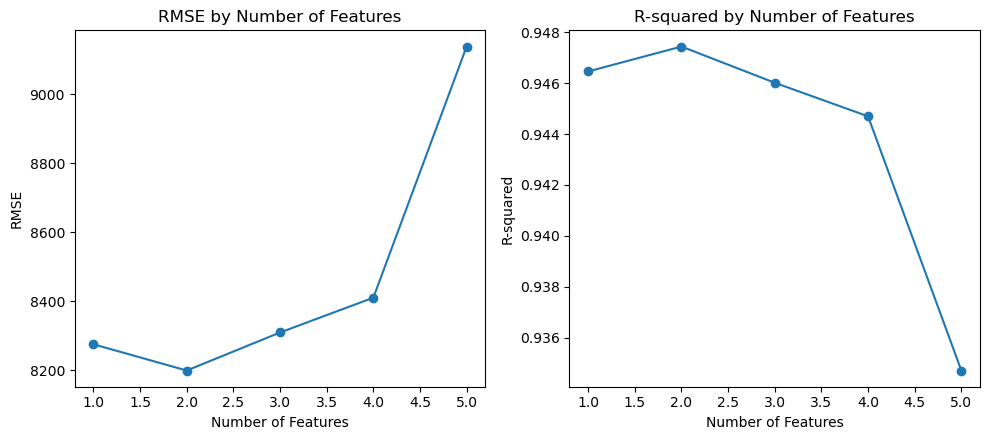

In [9]:
# 4. 繪製圖表 (RMSE by Number of Features 與 R-squared by Number of Features)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# 左圖：RMSE by Number of Features
axes[0].plot(results_df['Number of Features'], results_df['RMSE'], marker='o')
axes[0].set_title('RMSE by Number of Features')
axes[0].set_xlabel('Number of Features')
axes[0].set_ylabel('RMSE')

# 右圖：R-squared by Number of Features
axes[1].plot(results_df['Number of Features'], results_df['R-squared'], marker='o')
axes[1].set_title('R-squared by Number of Features')
axes[1].set_xlabel('Number of Features')
axes[1].set_ylabel('R-squared')

plt.tight_layout()
plt.show()

## 5. 前向選擇 (Forward) vs 後向消除 (Backward) vs 遞迴特徵消除 (RFE)

本單元透過 `sklearn.feature_selection` 比較三種主流的包裝法（Wrapper Methods）：
1. **前向選擇 (Sequential Forward Selection, SFS)**：由下而上（Bottom-up），每次加入最具貢獻之特徵。
2. **後向消除 (Sequential Backward Selection, SBS)**：由上而下（Top-down），每次剃除最無貢獻之特徵。
3. **遞迴特徵消除 (Recursive Feature Elimination, RFE)**：依據模型係數權重大小遞迴剔除最不重要特徵。

並分別繪製這三種演算法在不同特徵數量 $k$ 下的評估指標（RMSE 與 R-squared）圖表。

=== 三種特徵選擇方法之指標總表 ===


k,Forward RMSE,Forward R2,Backward RMSE,Backward R2,RFE RMSE,RFE R2
1,8274.8680,0.9465,8274.8680,0.9465,8274.8680,0.9465
2,8198.7972,0.9474,8198.7972,0.9474,8198.7972,0.9474
3,8803.7758,0.9394,8309.0597,0.9460,8803.7758,0.9394
4,8803.6864,0.9394,8409.9167,0.9447,9068.5412,0.9357
5,9137.9902,0.9347,8409.9167,0.9447,9137.9902,0.9347
6,9137.9902,0.9347,9137.9902,0.9347,9137.9902,0.9347


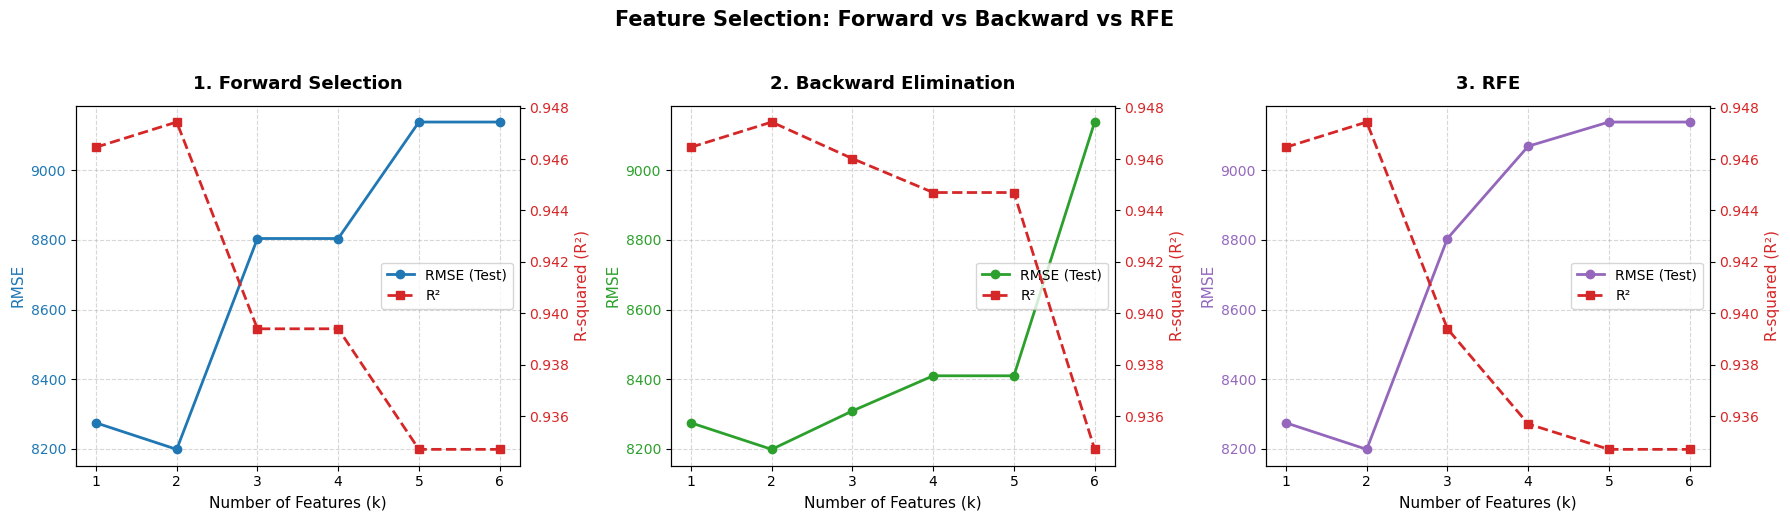

In [14]:
# 6. 執行三種特徵選擇演算法並分別顯示圖表
from sklearn.feature_selection import SequentialFeatureSelector, RFE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 準備特徵與目標變數
feature_cols = [c for c in train_df.columns if c != 'Profit']
X_train_full = train_df[feature_cols]
y_train_full = train_df['Profit']
X_test_full = test_df[feature_cols]
y_test_full = test_df['Profit']

# 特徵標準化 (供 RFE 依權重排序使用，避免尺度差異干擾係數絕對值)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_full)

total_p = len(feature_cols)
# 設定評估特徵數量 (最多至 Top 20 或總特徵數)
max_k = min(20, total_p)
k_range = list(range(1, max_k + 1))

# 儲存評估結果
history = {
    'Forward': {'k': [], 'features': [], 'RMSE': [], 'R2': []},
    'Backward': {'k': [], 'features': [], 'RMSE': [], 'R2': []},
    'RFE': {'k': [], 'features': [], 'RMSE': [], 'R2': []}
}

for k in k_range:
    # 1. 前向選擇 (Forward Selection)
    # 注意：當 k 等於總特徵數時，所有特徵皆被選中，直接取全特徵以避免 SFS 丟出 n_features_to_select < n_features 錯誤
    if k == total_p:
        feats_fwd = list(feature_cols)
    else:
        sfs_fwd = SequentialFeatureSelector(LinearRegression(), n_features_to_select=k, direction='forward', cv=5)
        sfs_fwd.fit(X_train_full, y_train_full)
        feats_fwd = list(X_train_full.columns[sfs_fwd.get_support()])
        
    m_fwd = LinearRegression().fit(X_train_full[feats_fwd], y_train_full)
    pred_fwd = m_fwd.predict(X_test_full[feats_fwd])
    history['Forward']['k'].append(k)
    history['Forward']['features'].append(feats_fwd)
    history['Forward']['RMSE'].append(np.sqrt(mean_squared_error(y_test_full, pred_fwd)))
    history['Forward']['R2'].append(r2_score(y_test_full, pred_fwd))
    
    # 2. 後向消除 (Backward Elimination)
    if k == total_p:
        feats_bwd = list(feature_cols)
    else:
        sfs_bwd = SequentialFeatureSelector(LinearRegression(), n_features_to_select=k, direction='backward', cv=5)
        sfs_bwd.fit(X_train_full, y_train_full)
        feats_bwd = list(X_train_full.columns[sfs_bwd.get_support()])
        
    m_bwd = LinearRegression().fit(X_train_full[feats_bwd], y_train_full)
    pred_bwd = m_bwd.predict(X_test_full[feats_bwd])
    history['Backward']['k'].append(k)
    history['Backward']['features'].append(feats_bwd)
    history['Backward']['RMSE'].append(np.sqrt(mean_squared_error(y_test_full, pred_bwd)))
    history['Backward']['R2'].append(r2_score(y_test_full, pred_bwd))
    
    # 3. 遞迴特徵消除 (RFE)
    rfe = RFE(estimator=LinearRegression(), n_features_to_select=k)
    rfe.fit(X_train_scaled, y_train_full)
    feats_rfe = list(X_train_full.columns[rfe.support_])
    m_rfe = LinearRegression().fit(X_train_full[feats_rfe], y_train_full)
    pred_rfe = m_rfe.predict(X_test_full[feats_rfe])
    history['RFE']['k'].append(k)
    history['RFE']['features'].append(feats_rfe)
    history['RFE']['RMSE'].append(np.sqrt(mean_squared_error(y_test_full, pred_rfe)))
    history['RFE']['R2'].append(r2_score(y_test_full, pred_rfe))

# 顯示評估指標總表
summary_records = []
for i, k in enumerate(k_range):
    summary_records.append({
        'k': k,
        'Forward RMSE': history['Forward']['RMSE'][i],
        'Forward R2': history['Forward']['R2'][i],
        'Backward RMSE': history['Backward']['RMSE'][i],
        'Backward R2': history['Backward']['R2'][i],
        'RFE RMSE': history['RFE']['RMSE'][i],
        'RFE R2': history['RFE']['R2'][i]
    })
summary_df = pd.DataFrame(summary_records)
print("=== 三種特徵選擇方法之指標總表 ===")
display(summary_df.style.hide(axis='index').format({
    'Forward RMSE': '{:.4f}', 'Forward R2': '{:.4f}',
    'Backward RMSE': '{:.4f}', 'Backward R2': '{:.4f}',
    'RFE RMSE': '{:.4f}', 'RFE R2': '{:.4f}'
}))

# 分別顯示這三個圖表 (1. 前向選擇, 2. 後向消除, 3. 遞迴特徵消除 RFE)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

methods = [
    ('1. Forward Selection', history['Forward'], '#1f77b4'),
    ('2. Backward Elimination', history['Backward'], '#2ca02c'),
    ('3. RFE', history['RFE'], '#9467bd')
]

for idx, (title, data, color_rmse) in enumerate(methods):
    ax = axes[idx]
    
    # 左 Y 軸：RMSE (越低越好)
    line1 = ax.plot(data['k'], data['RMSE'], marker='o', color=color_rmse, linewidth=2, label='RMSE (Test)')
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('Number of Features (k)', fontsize=11)
    ax.set_ylabel('RMSE', color=color_rmse, fontsize=11)
    ax.tick_params(axis='y', labelcolor=color_rmse)
    ax.set_xticks(data['k'])
    ax.grid(True, linestyle='--', alpha=0.5)
    
    # 右 Y 軸：R-squared (越高越好)
    ax_r2 = ax.twinx()
    line2 = ax_r2.plot(data['k'], data['R2'], marker='s', color='#d62728', linestyle='--', linewidth=2, label='R²')
    ax_r2.set_ylabel('R-squared (R²)', color='#d62728', fontsize=11)
    ax_r2.tick_params(axis='y', labelcolor='#d62728')
    
    # 整合雙軸圖例
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax.legend(lines, labels, loc='center right')

plt.suptitle('Feature Selection: Forward vs Backward vs RFE', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()